<a href="https://colab.research.google.com/github/derektorquette/estatistica-para-analise-de-dados-com-python/blob/main/11_estatistica_probabilistica_teste_de_hipotese_t.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **TESTE t PARA UMA AMOSTRA**

In [1]:
import numpy as np
import pandas as pd

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
enem_sp = pd.read_csv('/content/drive/MyDrive/Meus_Projetos/Estatística para Análise de Dados com Python - Udemy/enem_2019_tratado.csv',
                      sep=',', encoding='iso-8859-1')

In [4]:
enem_sp.head()

,NU_INSCRICAO,NO_MUNICIPIO_RESIDENCIA,IDADE,SEXO,TP_ESTADO_CIVIL,RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,ESCOLA,CO_ESCOLA,...,NOTA_MT,TP_LINGUA,TP_STATUS_REDACAO,COMP1,COMP2,COMP3,COMP4,COMP5,NOTA_REDACAO,INTERNET
0,"1,90E+11",Santa Isabel,22,M,1,parda,1,1,não_respondeu,NaN,...,600.2,Inglês,1.0,160.0,200.0,180.0,200.0,200.0,940.0,Sim
1,"1,90E+11",São Paulo,17,F,1,parda,1,2,privada,15567761.0,...,731.8,Inglês,1.0,160.0,120.0,200.0,200.0,200.0,880.0,Não
2,"1,90E+11",São Bernardo do Campo,19,M,1,parda,1,2,pública,35904958.0,...,393.2,Espanhol,1.0,80.0,160.0,120.0,100.0,100.0,560.0,Sim
3,"1,90E+11",Embu-Guaçu,17,F,1,parda,1,2,pública,NaN,...,419.2,Inglês,1.0,120.0,120.0,120.0,120.0,80.0,560.0,Sim
4,"1,90E+11",Guarulhos,23,F,1,branca,1,1,não_respondeu,NaN,...,796.1,Inglês,1.0,160.0,200.0,180.0,180.0,160.0,880.0,Sim


In [5]:
colegioy = enem_sp.loc[enem_sp.CO_ESCOLA == 35151506.0]

In [6]:
colegioy.shape

(30, 28)

In [7]:
colegioy.head()

,NU_INSCRICAO,NO_MUNICIPIO_RESIDENCIA,IDADE,SEXO,TP_ESTADO_CIVIL,RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,ESCOLA,CO_ESCOLA,...,NOTA_MT,TP_LINGUA,TP_STATUS_REDACAO,COMP1,COMP2,COMP3,COMP4,COMP5,NOTA_REDACAO,INTERNET
492,"1,90E+11",São Paulo,17,F,1,branca,1,2,privada,35151506.0,...,64.0,Inglês,1.0,160.0,160.0,140.0,140.0,120.0,720.0,Sim
7910,"1,90E+11",São Paulo,18,F,1,branca,1,2,privada,35151506.0,...,699.5,Inglês,1.0,160.0,120.0,160.0,160.0,140.0,740.0,Sim
14367,"1,90E+11",São Paulo,17,M,1,branca,1,2,privada,35151506.0,...,780.2,Inglês,1.0,120.0,120.0,100.0,140.0,160.0,640.0,Sim
22519,"1,90E+11",São Paulo,17,F,1,preta,1,2,privada,35151506.0,...,732.2,Inglês,1.0,140.0,120.0,140.0,180.0,120.0,700.0,Sim
58184,"1,90E+11",São Paulo,17,M,1,branca,1,2,privada,35151506.0,...,756.3,Inglês,1.0,160.0,200.0,200.0,200.0,200.0,960.0,Sim


1) Analisar a classificação das variáveis

In [8]:
colegioy.dtypes

,0
NU_INSCRICAO,object
NO_MUNICIPIO_RESIDENCIA,object
IDADE,int64
SEXO,object
TP_ESTADO_CIVIL,int64
RACA,object
TP_NACIONALIDADE,int64
TP_ST_CONCLUSAO,int64
ESCOLA,object
CO_ESCOLA,float64


In [10]:
colegioy.describe()

,IDADE,TP_ESTADO_CIVIL,TP_NACIONALIDADE,TP_ST_CONCLUSAO,CO_ESCOLA,TP_PRESENCA_CN,TP_PRESENCA_CH,TP_PRESENCA_LC,TP_PRESENCA_MT,NOTA_CN,NOTA_CH,NOTA_LC,NOTA_MT,TP_STATUS_REDACAO,COMP1,COMP2,COMP3,COMP4,COMP5,NOTA_REDACAO
count,30.000000,30.0,30.0,30.0,30.0,30.0,30.0,30.0,30.0,30.000000,30.000000,30.000000,30.000000,30.0,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000
mean,17.066667,1.0,1.0,2.0,35151506.0,1.0,1.0,1.0,1.0,547.610000,566.073333,483.546667,604.246667,1.0,142.000000,142.666667,141.333333,146.000000,144.000000,716.000000
std,0.253708,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,138.014056,148.074839,218.994111,240.086096,0.0,16.897255,25.587353,24.597916,22.984252,29.896373,93.867111
min,17.000000,1.0,1.0,2.0,35151506.0,1.0,1.0,1.0,1.0,60.100000,54.700000,53.500000,53.100000,1.0,120.000000,120.000000,100.000000,120.000000,80.000000,600.000000
25%,17.000000,1.0,1.0,2.0,35151506.0,1.0,1.0,1.0,1.0,555.425000,554.325000,508.000000,564.450000,1.0,120.000000,120.000000,120.000000,120.000000,120.000000,640.000000
50%,17.000000,1.0,1.0,2.0,35151506.0,1.0,1.0,1.0,1.0,571.550000,600.600000,592.250000,694.850000,1.0,140.000000,140.000000,140.000000,140.000000,140.000000,710.000000
75%,17.000000,1.0,1.0,2.0,35151506.0,1.0,1.0,1.0,1.0,602.225000,635.725000,604.400000,753.750000,1.0,160.000000,160.000000,160.000000,160.000000,160.000000,760.000000
max,18.000000,1.0,1.0,2.0,35151506.0,1.0,1.0,1.0,1.0,670.800000,723.900000,648.900000,882.500000,1.0,160.000000,200.000000,200.000000,200.000000,200.000000,960.000000


2) Analisar valores missing

In [11]:
colegioy.isnull().sum()

,0
NU_INSCRICAO,0
NO_MUNICIPIO_RESIDENCIA,0
IDADE,0
SEXO,0
TP_ESTADO_CIVIL,0
RACA,0
TP_NACIONALIDADE,0
TP_ST_CONCLUSAO,0
ESCOLA,0
CO_ESCOLA,0


3) Analisar outliers

In [12]:
import plotly.express as px

In [13]:
grafico = px.box(colegioy, y="NOTA_REDACAO")
grafico.show()

4) Analisar Normalidade - o histograma não é o ideal para análises de normalidade, no entanto, podemos notar uma distribuição assímetrica a direita.

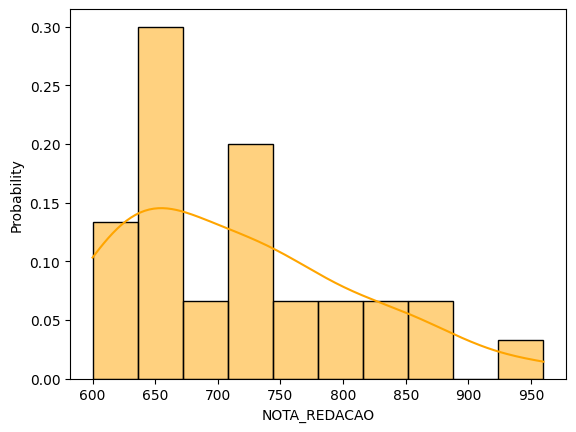

In [14]:
import seaborn as sns
sns.histplot(colegioy, x='NOTA_REDACAO', bins=10, color="orange", kde=True, stat="probability");

In [15]:
import scipy.stats as stats
import matplotlib.pyplot as plt

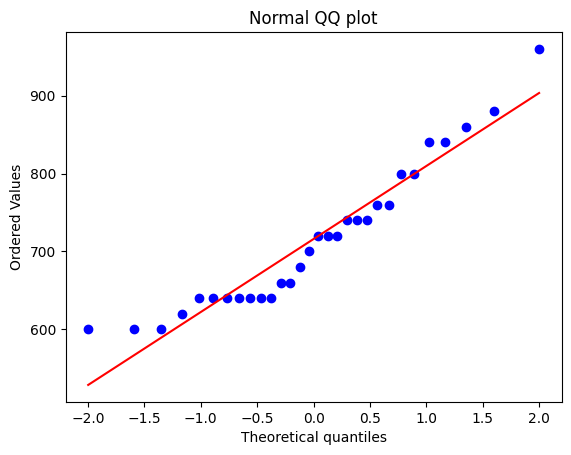

In [17]:
stats.probplot(colegioy['NOTA_REDACAO'], dist="norm", plot=plt)
plt.title("Normal QQ plot")
plt.show()

CRITÉRIOS:

NÍVEL DE SIGNIFICÂNCIA DE 0,05 ou 5% (MAIS UTILIZADO)

QUANDO p > 0,05 (distribuição normal).

In [18]:
# Teste Shapiro-Wilk - limitação de 5 mil registro
stats.shapiro(colegioy.NOTA_REDACAO)

ShapiroResult(statistic=np.float64(0.9185916932947775), pvalue=np.float64(0.024660758263151155))

In [19]:
import statsmodels
from statsmodels.stats.diagnostic import lilliefors

In [20]:
# Teste Lilliefors (Kolmogorov_Sminorv)
statsmodels.stats.diagnostic.lilliefors(colegioy.NOTA_REDACAO, dist = 'norm')

(np.float64(0.15794211976028916), np.float64(0.052842042822119004))

**TESTE t**

Média das notas de redação do colégio Y, comparada a média do Estado de São Paulo.

Ho = média é igual a de São Paulo : p > 0.05

Ha = média é diferente da de São Paulo : p <= 0.05

In [21]:
enem_sp.NOTA_REDACAO.describe()

,NOTA_REDACAO
count,499940.000000
mean,593.018322
std,170.536724
min,0.000000
25%,500.000000
50%,600.000000
75%,680.000000
max,1000.000000


In [22]:
import scipy.stats as stats

In [23]:
stat, p = stats.ttest_1samp(colegioy['NOTA_REDACAO'], popmean=593.018)
print('Estatística de teste: {}'.format(stat.round(2)))
print('p-valor: {}'.format(p.round(10)))

Estatística de teste: 7.18
p-valor: 6.72e-08


In [24]:
colegioy.NOTA_REDACAO.describe()

,NOTA_REDACAO
count,30.000000
mean,716.000000
std,93.867111
min,600.000000
25%,640.000000
50%,710.000000
75%,760.000000
max,960.000000


**INTERPRETAÇÃO:**

Teste estatístico: t = 7,18

p_valor = 6.72e-08

Conclusão: No nível de significância de 0,05, não há evidências para assumir que a média de redação do colégio y seja igual a média do Estado de São Paulo.

